# Phase 5 – Customer Purchase Cycle Analysis

How frequently do customers naturally repurchase?

## Why is this analysis important?
Before defining churn, we need to understand the normal customer buying cycle.

## Expected Outputs
- Average repurchase interval
- Median repurchase interval
- Purchase interval distribution
- Recommended churn threshold

## Business Value
Provides an evidence-based churn definition instead of choosing an arbitrary inactivity period.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

FILE_PATH="/content/drive/MyDrive/Revenue_Intelligence_Project/Data/customer_analytics.csv"

Mounted at /content/drive


In [2]:
df=pd.read_csv(FILE_PATH)

df["InvoiceDate"]=pd.to_datetime(df["InvoiceDate"])

print(df.shape)

df.head()

(779495, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [3]:
df=df.sort_values(
    by=[
        "Customer ID",
        "InvoiceDate"
    ]
)

In [4]:
df["PreviousPurchase"]=(
    df.groupby("Customer ID")["InvoiceDate"]
      .shift(1)
)

In [5]:
df["DaysBetweenPurchases"]=(
    df["InvoiceDate"]
    -
    df["PreviousPurchase"]
).dt.days

In [6]:
df[
[
"Customer ID",
"InvoiceDate",
"PreviousPurchase",
"DaysBetweenPurchases"
]
].head(20)

,Customer ID,InvoiceDate,PreviousPurchase,DaysBetweenPurchases
20724,12346.0,2009-12-14 08:34:00,NaT,NaN
20967,12346.0,2009-12-14 11:00:00,2009-12-14 08:34:00,0.0
20968,12346.0,2009-12-14 11:02:00,2009-12-14 11:00:00,0.0
27607,12346.0,2009-12-18 10:47:00,2009-12-14 11:02:00,3.0
27618,12346.0,2009-12-18 10:55:00,2009-12-18 10:47:00,0.0
30279,12346.0,2010-01-04 09:24:00,2009-12-18 10:55:00,16.0
30280,12346.0,2010-01-04 09:53:00,2010-01-04 09:24:00,0.0
36691,12346.0,2010-01-14 13:50:00,2010-01-04 09:53:00,10.0
43488,12346.0,2010-01-22 13:30:00,2010-01-14 13:50:00,7.0
76169,12346.0,2010-03-02 13:08:00,2010-01-22 13:30:00,38.0


In [7]:
purchase_intervals=df[
    df["DaysBetweenPurchases"].notna()
]

In [8]:
purchase_intervals[
"DaysBetweenPurchases"
].describe()

,DaysBetweenPurchases
count,773614.000000
mean,2.059276
std,18.218176
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,714.000000


In [9]:
purchase_intervals[
"DaysBetweenPurchases"
].quantile(
[0.25,0.50,0.75,0.90]
)

,DaysBetweenPurchases
0.25,0.0
0.50,0.0
0.75,0.0
0.90,0.0


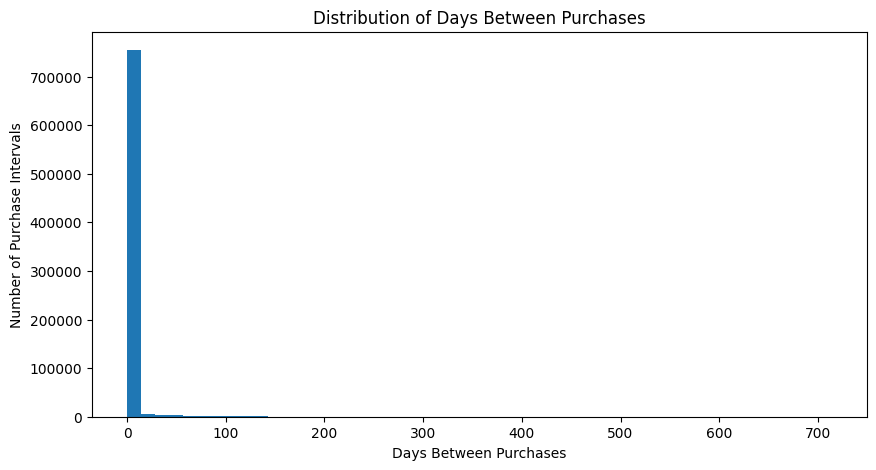

In [10]:
plt.figure(figsize=(10,5))

plt.hist(
    purchase_intervals["DaysBetweenPurchases"],
    bins=50
)

plt.title("Distribution of Days Between Purchases")
plt.xlabel("Days Between Purchases")
plt.ylabel("Number of Purchase Intervals")

plt.show()

Create Order-Level Dataset

In [11]:
orders = (
    df.groupby(
        ["Customer ID", "Invoice"]
    )
    .agg(
        {
            "InvoiceDate": "min",
            "Revenue": "sum"
        }
    )
    .reset_index()
)

orders.head()

,Customer ID,Invoice,InvoiceDate,Revenue
0,12346.0,491725,2009-12-14 08:34:00,45.0
1,12346.0,491742,2009-12-14 11:00:00,22.5
2,12346.0,491744,2009-12-14 11:02:00,22.5
3,12346.0,492718,2009-12-18 10:47:00,22.5
4,12346.0,492722,2009-12-18 10:55:00,1.0


In [12]:
print(orders.shape)

orders.head(10)

(36975, 4)


,Customer ID,Invoice,InvoiceDate,Revenue
0,12346.0,491725,2009-12-14 08:34:00,45.00
1,12346.0,491742,2009-12-14 11:00:00,22.50
2,12346.0,491744,2009-12-14 11:02:00,22.50
3,12346.0,492718,2009-12-18 10:47:00,22.50
4,12346.0,492722,2009-12-18 10:55:00,1.00
5,12346.0,493410,2010-01-04 09:24:00,22.50
6,12346.0,493412,2010-01-04 09:53:00,22.50
7,12346.0,494450,2010-01-14 13:50:00,22.50
8,12346.0,495295,2010-01-22 13:30:00,22.50
9,12346.0,499763,2010-03-02 13:08:00,27.05


In [13]:
orders = orders.sort_values(
    by=[
        "Customer ID",
        "InvoiceDate"
    ]
)

In [14]:
orders["PreviousOrderDate"] = (
    orders.groupby("Customer ID")["InvoiceDate"]
          .shift(1)
)

In [15]:
orders["DaysBetweenOrders"] = (
    orders["InvoiceDate"]
    -
    orders["PreviousOrderDate"]
).dt.days

In [16]:
orders[
[
"Customer ID",
"Invoice",
"InvoiceDate",
"PreviousOrderDate",
"DaysBetweenOrders"
]
].head(20)

,Customer ID,Invoice,InvoiceDate,PreviousOrderDate,DaysBetweenOrders
0,12346.0,491725,2009-12-14 08:34:00,NaT,NaN
1,12346.0,491742,2009-12-14 11:00:00,2009-12-14 08:34:00,0.0
2,12346.0,491744,2009-12-14 11:02:00,2009-12-14 11:00:00,0.0
3,12346.0,492718,2009-12-18 10:47:00,2009-12-14 11:02:00,3.0
4,12346.0,492722,2009-12-18 10:55:00,2009-12-18 10:47:00,0.0
5,12346.0,493410,2010-01-04 09:24:00,2009-12-18 10:55:00,16.0
6,12346.0,493412,2010-01-04 09:53:00,2010-01-04 09:24:00,0.0
7,12346.0,494450,2010-01-14 13:50:00,2010-01-04 09:53:00,10.0
8,12346.0,495295,2010-01-22 13:30:00,2010-01-14 13:50:00,7.0
9,12346.0,499763,2010-03-02 13:08:00,2010-01-22 13:30:00,38.0


In [17]:
order_intervals = orders[
    orders["DaysBetweenOrders"].notna()
]

In [18]:
order_intervals[
"DaysBetweenOrders"
].describe()

,DaysBetweenOrders
count,31094.000000
mean,51.234483
std,75.752077
min,0.000000
25%,6.000000
50%,24.000000
75%,61.000000
max,714.000000


In [19]:
order_intervals[
"DaysBetweenOrders"
].quantile(
[0.25,0.50,0.75,0.90]
)

,DaysBetweenOrders
0.25,6.0
0.50,24.0
0.75,61.0
0.90,134.0


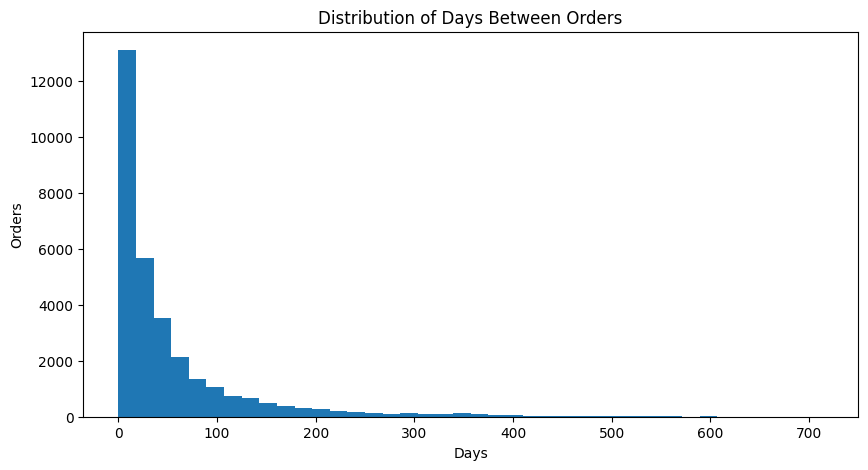

In [20]:
plt.figure(figsize=(10,5))

plt.hist(
    order_intervals["DaysBetweenOrders"],
    bins=40
)

plt.title("Distribution of Days Between Orders")

plt.xlabel("Days")

plt.ylabel("Orders")

plt.show()

In [21]:
snapshot_date = orders["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_last_purchase = (
    orders.groupby("Customer ID")
          .agg({
              "InvoiceDate": "max"
          })
          .reset_index()
)

customer_last_purchase["DaysSinceLastPurchase"] = (
    snapshot_date -
    customer_last_purchase["InvoiceDate"]
).dt.days

customer_last_purchase.head()

,Customer ID,InvoiceDate,DaysSinceLastPurchase
0,12346.0,2011-01-18 10:01:00,326
1,12347.0,2011-12-07 15:52:00,2
2,12348.0,2011-09-25 13:13:00,75
3,12349.0,2011-11-21 09:51:00,19
4,12350.0,2011-02-02 16:01:00,310


In [22]:
thresholds = [60, 90, 120]

results = []

total_customers = len(customer_last_purchase)

for threshold in thresholds:

    churned = (
        customer_last_purchase["DaysSinceLastPurchase"]
        > threshold
    ).sum()

    active = total_customers - churned

    churn_rate = (
        churned / total_customers
    ) * 100

    results.append([
        threshold,
        active,
        churned,
        round(churn_rate,2)
    ])

threshold_summary = pd.DataFrame(
    results,
    columns=[
        "Threshold (Days)",
        "Active Customers",
        "Churned Customers",
        "Churn Rate (%)"
    ]
)

threshold_summary

,Threshold (Days),Active Customers,Churned Customers,Churn Rate (%)
0,60,2397,3484,59.24
1,90,2890,2991,50.86
2,120,3122,2759,46.91


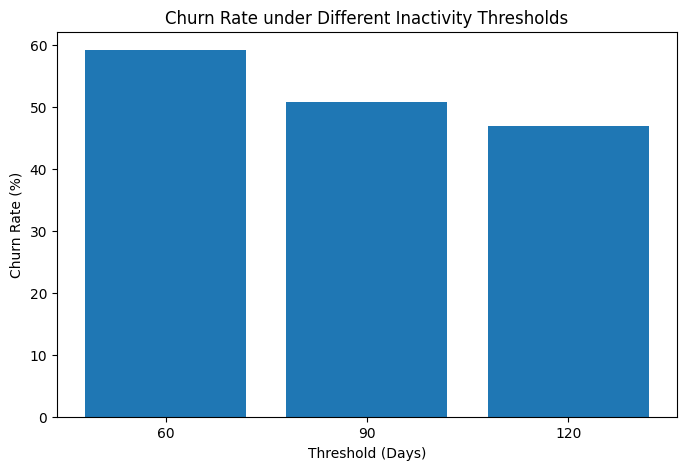

In [23]:
plt.figure(figsize=(8,5))

plt.bar(
    threshold_summary["Threshold (Days)"].astype(str),
    threshold_summary["Churn Rate (%)"]
)

plt.title("Churn Rate under Different Inactivity Thresholds")

plt.xlabel("Threshold (Days)")

plt.ylabel("Churn Rate (%)")

plt.show()

In [24]:
orders.to_csv(
"/content/drive/MyDrive/Revenue_Intelligence_Project/Data/orders.csv",
index=False
)

order_intervals.to_csv(
"/content/drive/MyDrive/Revenue_Intelligence_Project/Data/order_intervals.csv",
index=False
)

print("Files Saved Successfully")

Files Saved Successfully
